In [1]:
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 42                 # same seed = same result every time
IMG_SIZE = (256, 256)     # (width, height)
BATCH_SIZE = 8
MASK_THRESHOLD = 127      # mask pixel above this = foreground

rng = np.random.default_rng(SEED)

from pathlib import Path
# Dynamic multi-directional project root resolver
here = Path.cwd().resolve()
ROOT = None
for candidate in [here, *here.parents, here / "SIH2026-main"]:
    if candidate.is_dir() and (candidate / "dataset").is_dir() and (candidate / "ml").is_dir():
        ROOT = candidate.resolve()
        break
if ROOT is None:
    for d in here.glob("**/ml"):
        if (d.parent / "dataset").is_dir():
            ROOT = d.parent.resolve()
            break
assert ROOT is not None, "Project root not found (must contain 'dataset' and 'ml')"

IMG_DIR = ROOT / "dataset" / "Ml_project_dataset" / "images" / "images"
MASK_DIR = ROOT / "dataset" / "Ml_project_dataset" / "masks" / "masks"
OUT = ROOT / "ml" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

assert IMG_DIR.is_dir() and MASK_DIR.is_dir(), "Image or mask folder not found"
print("Project folder:", ROOT)
print("Images folder:", IMG_DIR.exists())
print("Masks folder:", MASK_DIR.exists())


Project folder: C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main
Images folder: True
Masks folder: True


## Match every image with its mask

In [2]:
EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

def list_files(folder):
    """Give back a dictionary: {name without extension: full path}"""
    files = {}
    for p in folder.rglob("*"):
        if p.suffix.lower() in EXTENSIONS:
            name = p.relative_to(folder).with_suffix("").as_posix().lower()
            # if two files have the same name (a.png and a.jpg) one would be lost
            assert name not in files, f"Two files have the same name: {name}"
            files[name] = p
    return files

images = list_files(IMG_DIR)
masks = list_files(MASK_DIR)
names = sorted(images.keys() & masks.keys())

print("images:", len(images), "| masks:", len(masks), "| matched:", len(names))
print("images without mask:", len(images.keys() - masks.keys()))
print("masks without image:", len(masks.keys() - images.keys()))
assert len(names) > 0, "No image-mask pairs found"

df = pd.DataFrame({
    "image_path": [str(images[n]) for n in names],
    "mask_path": [str(masks[n]) for n in names],
})

# The dataset's own split (train / val / test) is read from the folder name
def find_split(name):
    for part in name.split("/")[:-1]:
        if part in ("train", "val", "test"):
            return part
    return "unspecified"

df["split"] = [find_split(n) for n in names]
print(df["split"].value_counts())

images: 8070 | masks: 8070 | matched: 8070
images without mask: 0
masks without image: 0
split
train    6455
val      1615
Name: count, dtype: int64


##  Check the files

In [3]:
def check_pair(row):
    """Returns: ok, width, height, mode, hash"""
    try:
        with Image.open(row.image_path) as img, Image.open(row.mask_path) as mask:
            img.load()    
            mask.load()
            same_size = (img.size == mask.size)
            file_hash = hashlib.md5(Path(row.image_path).read_bytes()).hexdigest()
            return same_size, img.size[0], img.size[1], img.mode, file_hash
    except Exception:
        return False, 0, 0, "error", ""

df[["ok", "w", "h", "mode", "hash"]] = [check_pair(r) for r in df.itertuples()]
df["ok"] = df["ok"].astype(bool)

print("Image modes:", df["mode"].value_counts().to_dict())
print("Image sizes:", df.groupby(["w", "h"]).size().to_dict())
print("Broken or mismatched pairs:", (~df.ok).sum())

df = df[df.ok].reset_index(drop=True)
print("Good pairs:", len(df))

Image modes: {'RGB': 8070}
Image sizes: {(256, 256): 8070}
Broken or mismatched pairs: 0
Good pairs: 8070


## Remove duplicates

In [4]:
order = {"test": 0, "val": 1, "train": 2, "unspecified": 3}
df = df.sort_values("split", key=lambda s: s.map(order))   # test and val come first

before = len(df)
df = df.drop_duplicates("hash").reset_index(drop=True)     # keeps the first copy
print("Duplicates removed:", before - len(df))
print("Pairs left:", len(df))

Duplicates removed: 0
Pairs left: 8070


## Look at the masks (to choose the threshold)

Grey pixels (not 0 or 255): 1.14%
Foreground if threshold = 0: 25.22%
Foreground if threshold = 127: 24.63%
Foreground if threshold = 254: 24.08%


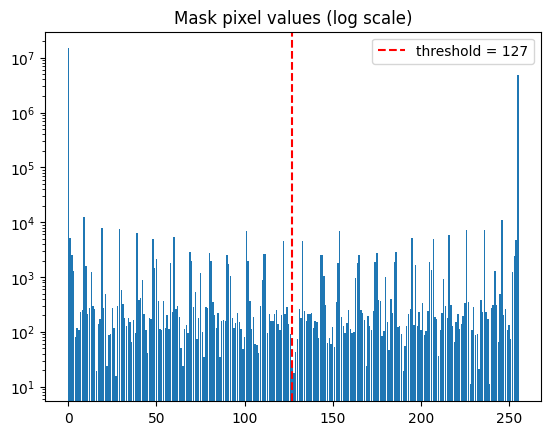

In [5]:
sample = df.sample(min(300, len(df)), random_state=SEED)

hist = np.zeros(256, dtype=np.int64)       # how many pixels have each value 0..255
for path in sample.mask_path:
    with Image.open(path) as m:
        pixels = np.asarray(m.convert("L")).ravel()
        hist += np.bincount(pixels, minlength=256)

total = hist.sum()
grey = hist[1:255].sum() / total
print(f"Grey pixels (not 0 or 255): {grey:.2%}")
for t in (0, 127, 254):
    print(f"Foreground if threshold = {t}: {hist[t+1:].sum() / total:.2%}")

# Masks must be (almost) only black and white. If not, they may have more than 2 classes
assert grey < 0.05, "Masks have many grey values - check if they have more than 2 classes"

plt.bar(range(256), hist)
plt.yscale("log")
plt.axvline(MASK_THRESHOLD, color="red", linestyle="--", label=f"threshold = {MASK_THRESHOLD}")
plt.title("Mask pixel values (log scale)")
plt.legend()
plt.show()

## Train / val / test split

In [6]:
splits_in_data = set(df.split)

if splits_in_data == {"unspecified"}:
    train_part, rest = train_test_split(df, test_size=0.30, random_state=SEED)
    val_part, test_part = train_test_split(rest, test_size=0.50, random_state=SEED)
    df.loc[train_part.index, "split"] = "train"
    df.loc[val_part.index, "split"] = "val"
    df.loc[test_part.index, "split"] = "test"
elif "test" not in splits_in_data:
    _, test_part = train_test_split(df[df.split == "val"], test_size=0.5, random_state=SEED)
    df.loc[test_part.index, "split"] = "test"

print(df.split.value_counts())
assert {"train", "val", "test"} <= set(df.split), "One split is missing"

split
train    6455
test      808
val       807
Name: count, dtype: int64


##  Load function and normalization numbers

In [7]:
def load_pair(image_path, mask_path):
    img = Image.open(image_path).convert("RGB").resize(IMG_SIZE, Image.Resampling.BILINEAR)
    mask = Image.open(mask_path).convert("L").resize(IMG_SIZE, Image.Resampling.NEAREST)

    x = np.asarray(img, dtype=np.float32) / 255.0                        # shape (H, W, 3)
    y = (np.asarray(mask) > MASK_THRESHOLD).astype(np.float32)[..., None]  # shape (H, W, 1)
    return x, y

train_df = df[df.split == "train"]
# Use up to 500 random train images to find mean and std (per channel).
# We add up the numbers in float64 (very exact). With float32 the sum gets
# rounded wrongly because there are millions of pixels, and mean/std come out wrong.
stat_rows = train_df.sample(min(500, len(train_df)), random_state=SEED)

total = np.zeros(3, dtype=np.float64)       # sum of pixel values, per channel
total_sq = np.zeros(3, dtype=np.float64)    # sum of squared pixel values, per channel
pixel_count = 0

for r in stat_rows.itertuples():
    x, _ = load_pair(r.image_path, r.mask_path)
    x = x.astype(np.float64)
    total += x.sum(axis=(0, 1))
    total_sq += (x ** 2).sum(axis=(0, 1))
    pixel_count += x.shape[0] * x.shape[1]

MEAN = total / pixel_count
STD = np.sqrt(total_sq / pixel_count - MEAN ** 2) + 1e-7
print("Mean per channel:", MEAN.round(3))
print("Std per channel: ", STD.round(3))

# Check: after normalizing, mean should be about 0 and std about 1
check_rows = stat_rows.head(100)
check_images = np.stack([load_pair(r.image_path, r.mask_path)[0] for r in check_rows.itertuples()])
check = (check_images - MEAN) / STD
check_mean = check.mean(dtype=np.float64)
check_std = check.std(dtype=np.float64)
print("After normalizing -> mean: %.3f, std: %.3f" % (check_mean, check_std))
assert abs(check_mean) < 0.05 and abs(check_std - 1) < 0.05, "Normalization looks wrong"

# If all 3 channels have the same mean, the image is really grayscale
if np.allclose(MEAN, MEAN[0], atol=1e-3):
    print("Note: all 3 channels are the same -> the images are grayscale copied 3 times")

Mean per channel: [0.424 0.424 0.424]
Std per channel:  [0.214 0.214 0.214]
After normalizing -> mean: 0.045, std: 1.009
Note: all 3 channels are the same -> the images are grayscale copied 3 times


## Class balance

In [8]:
def foreground_share(mask_path):
    with Image.open(mask_path) as m:
        small = m.convert("L").resize(IMG_SIZE, Image.Resampling.NEAREST)
        return (np.asarray(small) > MASK_THRESHOLD).mean()

df["fg"] = [foreground_share(p) for p in df.mask_path]

summary = df.groupby("split")["fg"].agg(
    mean_foreground="mean",
    empty_masks=lambda s: (s == 0).mean(),
)
print(summary.round(4))

p = df[df.split == "train"].fg.mean()                # foreground share in train
POS_WEIGHT = float((1 - p) / max(p, 1e-7))           # background pixels per foreground pixel
print(f"Foreground in train: {p:.2%}  ->  pos_weight = {POS_WEIGHT:.2f}")


       mean_foreground  empty_masks
split                              
test            0.2835       0.0408
train           0.2494       0.0395
val             0.2574       0.0533
Foreground in train: 24.94%  ->  pos_weight = 3.01


## Augmentation

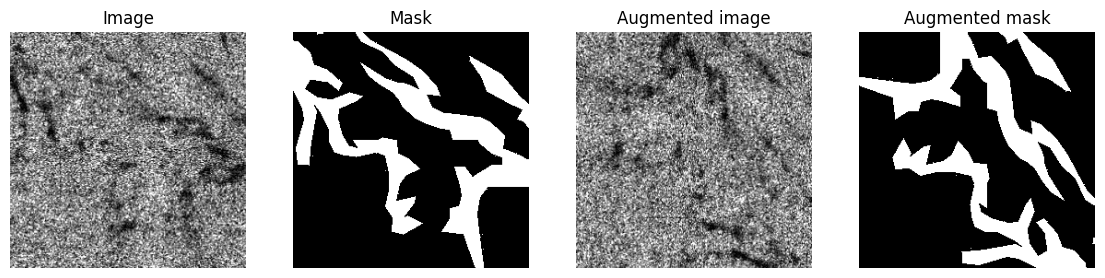

In [9]:
def augment(x, y, rng):
    if rng.random() < 0.5:                 # flip left-right
        x, y = x[:, ::-1], y[:, ::-1]
    if rng.random() < 0.5:                 # flip up-down
        x, y = x[::-1], y[::-1]
    k = rng.integers(4)                    # turn 0, 90, 180 or 270 degrees
    x = np.ascontiguousarray(np.rot90(x, k))
    y = np.ascontiguousarray(np.rot90(y, k))
    return x, y

# Test: image and mask must move together
test_array = np.random.default_rng(1).random((8, 8, 1)).astype(np.float32)
a, b = augment(test_array, test_array.copy(), np.random.default_rng(3))
assert np.array_equal(a, b), "Image and mask moved differently!"

# Look at one example
row = df[df.split == "train"].iloc[0]
x, y = load_pair(row.image_path, row.mask_path)
aug_x, aug_y = augment(x, y, rng)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
pictures = [x, y[..., 0], aug_x, aug_y[..., 0]]
titles = ["Image", "Mask", "Augmented image", "Augmented mask"]
for ax, pic, title in zip(axes, pictures, titles):
    ax.imshow(pic, cmap="gray" if pic.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## Batch Generator


In [10]:
def batches(data, shuffle=False, augmenting=False):
    data = data.reset_index(drop=True)
    order = rng.permutation(len(data)) if shuffle else np.arange(len(data))

    for start in range(0, len(order), BATCH_SIZE):
        ids = order[start:start + BATCH_SIZE]
        pairs = []
        for i in ids:
            x, y = load_pair(data.image_path[i], data.mask_path[i])
            if augmenting:
                x, y = augment(x, y, rng)
            pairs.append((x, y))

        X = np.stack([p[0] for p in pairs])
        Y = np.stack([p[1] for p in pairs])
        yield (X - MEAN) / STD, Y

X, Y = next(batches(train_df, shuffle=True, augmenting=True))
print("X:", X.shape, X.dtype)
print("Y:", Y.shape, Y.dtype, "| values:", np.unique(Y))

expected = (min(BATCH_SIZE, len(train_df)), IMG_SIZE[1], IMG_SIZE[0], 3)
assert X.shape == expected, "Wrong image batch shape"
assert not np.isnan(X).any(), "NaN found in images"
assert set(np.unique(Y)) <= {0.0, 1.0}, "Masks must be only 0 and 1"
print("Batch checks passed")

X: (8, 256, 256, 3) float64
Y: (8, 256, 256, 1) float32 | values: [0. 1.]
Batch checks passed


##  Save

In [11]:
out = df.drop(columns=["ok", "w", "h", "mode"]).copy()
for col in ["image_path", "mask_path"]:
    out[col] = out[col].map(lambda p: Path(p).relative_to(ROOT).as_posix())
out.to_csv(OUT / "dataset_splits.csv", index=False)

config = {
    "seed": SEED,
    "img_size": list(IMG_SIZE),
    "mask_threshold": MASK_THRESHOLD,
    "batch_size": BATCH_SIZE,
    "mean": MEAN.tolist(),
    "std": STD.tolist(),
    "pos_weight": POS_WEIGHT,
    "counts": df.split.value_counts().to_dict(),
}
(OUT / "preprocess_config.json").write_text(json.dumps(config, indent=2))

print("Saved in:", OUT)
print(json.dumps(config, indent=2))

Saved in: C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main\ml\processed
{
  "seed": 42,
  "img_size": [
    256,
    256
  ],
  "mask_threshold": 127,
  "batch_size": 8,
  "mean": [
    0.42435854638949455,
    0.42435854638949455,
    0.42435854638949455
  ],
  "std": [
    0.21396083519354342,
    0.21396083519354342,
    0.21396083519354342
  ],
  "pos_weight": 3.008870415448105,
  "counts": {
    "train": 6455,
    "test": 808,
    "val": 807
  }
}
